In [6]:
import sys
import sqlite3
import random
import os
import time
from datetime import datetime, date, timedelta
from faker import Faker
import pandas as pd

print("✓ Imports successful")
print("Python:", sys.version.split()[0])
print("SQLite:", sqlite3.sqlite_version)


DB_NAME = "university_registration.db"


try:
    conn.close()
except (NameError, sqlite3.Error):
    pass


if os.path.exists(DB_NAME):
    try:
        os.remove(DB_NAME)
        print(f"Removed old {DB_NAME}")
    except PermissionError:
        DB_NAME = f"university_registration_{datetime.now().strftime('%Y%m%d_%H%M%S')}.db"
        print(f"Database is locked by another process. Using {DB_NAME}")

fake = Faker("en_GB")
random.seed(42)
Faker.seed(42)

conn = sqlite3.connect(DB_NAME, timeout=30)
conn.execute("PRAGMA foreign_keys = ON")
cursor = conn.cursor()


for table in ["course_prerequisites", "enrollment", "courses",
              "instructors", "students", "departments"]:
    cursor.execute(f"DROP TABLE IF EXISTS {table}")


cursor.execute("""
CREATE TABLE departments (
    department_id INTEGER PRIMARY KEY AUTOINCREMENT,
    department_name TEXT NOT NULL UNIQUE,
    building TEXT NOT NULL,
    annual_budget REAL NOT NULL CHECK(annual_budget > 0),
    created_date DATE NOT NULL
)
""")

cursor.execute("""
CREATE TABLE students (
    student_id INTEGER PRIMARY KEY AUTOINCREMENT,
    first_name TEXT NOT NULL,
    last_name TEXT NOT NULL,
    email TEXT UNIQUE,
    phone TEXT,
    date_of_birth DATE NOT NULL,
    enrollment_date DATE NOT NULL,
    academic_level TEXT NOT NULL CHECK(academic_level IN
        ('Foundation','Undergraduate Year 1','Undergraduate Year 2',
         'Undergraduate Year 3','Postgraduate')),
    gpa REAL CHECK(gpa IS NULL OR (gpa >= 0.0 AND gpa <= 4.0)),
    department_id INTEGER,
    is_international INTEGER DEFAULT 0 CHECK(is_international IN (0,1)),
    tuition_balance REAL DEFAULT 0.0 CHECK(tuition_balance >= 0),
    CHECK (julianday(enrollment_date) >= julianday(date_of_birth) + 365.25 * 15),
    FOREIGN KEY (department_id) REFERENCES departments(department_id)
        ON DELETE SET NULL ON UPDATE CASCADE
)
""")

cursor.execute("""
CREATE TABLE instructors (
    instructor_id INTEGER PRIMARY KEY AUTOINCREMENT,
    first_name TEXT NOT NULL,
    last_name TEXT NOT NULL,
    email TEXT UNIQUE,
    department_id INTEGER NOT NULL,
    hire_date DATE NOT NULL,
    salary REAL NOT NULL CHECK(salary > 0),
    is_full_time INTEGER DEFAULT 1 CHECK(is_full_time IN (0,1)),
    office_location TEXT,
    FOREIGN KEY (department_id) REFERENCES departments(department_id)
        ON DELETE RESTRICT ON UPDATE CASCADE
)
""")

cursor.execute("""
CREATE TABLE courses (
    course_id INTEGER PRIMARY KEY AUTOINCREMENT,
    course_code TEXT NOT NULL UNIQUE,
    course_name TEXT NOT NULL,
    credit_hours INTEGER NOT NULL CHECK(credit_hours BETWEEN 1 AND 6),
    max_enrollment INTEGER NOT NULL CHECK(max_enrollment > 0),
    current_enrollment INTEGER DEFAULT 0 CHECK(current_enrollment >= 0),
    difficulty_level TEXT NOT NULL CHECK(difficulty_level IN
        ('Introductory','Intermediate','Advanced','Expert')),
    instructor_id INTEGER,
    department_id INTEGER NOT NULL,
    semester TEXT NOT NULL CHECK(semester IN ('Autumn','Spring','Summer')),
    year INTEGER NOT NULL CHECK(year BETWEEN 2020 AND 2025),
    CHECK (current_enrollment <= max_enrollment),
    FOREIGN KEY (instructor_id) REFERENCES instructors(instructor_id)
        ON DELETE SET NULL ON UPDATE CASCADE,
    FOREIGN KEY (department_id) REFERENCES departments(department_id)
        ON DELETE RESTRICT ON UPDATE CASCADE
)
""")

cursor.execute("""
CREATE TABLE enrollment (
    student_id INTEGER NOT NULL,
    course_id INTEGER NOT NULL,
    enrollment_date DATE NOT NULL,
    grade TEXT CHECK(grade IS NULL OR grade IN
        ('A+','A','A-','B+','B','B-','C+','C','C-','D+','D','F','W','I')),
    attendance_percentage REAL CHECK(attendance_percentage BETWEEN 0 AND 100),
    PRIMARY KEY (student_id, course_id),
    FOREIGN KEY (student_id) REFERENCES students(student_id)
        ON DELETE CASCADE ON UPDATE CASCADE,
    FOREIGN KEY (course_id) REFERENCES courses(course_id)
        ON DELETE CASCADE ON UPDATE CASCADE
)
""")

cursor.execute("""
CREATE TABLE course_prerequisites (
    course_id                INTEGER NOT NULL,
    prerequisite_course_id   INTEGER NOT NULL,
    required_or_recommended  TEXT NOT NULL
        CHECK(required_or_recommended IN ('Required','Recommended')),
    min_grade TEXT CHECK(min_grade IS NULL OR min_grade IN
        ('A+','A','A-','B+','B','B-','C+','C','C-','D+','D')),
    PRIMARY KEY (course_id, prerequisite_course_id),
    CHECK (course_id <> prerequisite_course_id),
    FOREIGN KEY (course_id) REFERENCES courses(course_id)
        ON DELETE CASCADE ON UPDATE CASCADE,
    FOREIGN KEY (prerequisite_course_id) REFERENCES courses(course_id)
        ON DELETE CASCADE ON UPDATE CASCADE
)
""")
conn.commit()
print("✓ 6 tables created")


departments = [
    ('Computer Science', 'Turing Building', 2500000.00, '1975-09-01'),
    ('Mathematics', 'Newton Hall', 1800000.00, '1960-09-01'),
    ('Physics', 'Einstein Centre', 3200000.00, '1955-09-01'),
    ('Business Studies', 'Adam Smith Building', 2100000.00, '1985-09-01'),
    ('Psychology', 'Freud Wing', 1500000.00, '1970-09-01'),
    ('Engineering', 'Brunel Complex', 4500000.00, '1965-09-01'),
]
cursor.executemany("""
INSERT INTO departments (department_name, building, annual_budget, created_date)
VALUES (?, ?, ?, ?)
""", departments)
conn.commit()
print(f"✓ {len(departments)} departments inserted")


used_emails = set()

def make_unique_email(first_name, last_name):
    base = f"{first_name.lower()}.{last_name.lower()}"
    candidate = f"{base}{random.randint(1, 99)}@university.ac.uk"
    while candidate in used_emails:
        candidate = f"{base}{random.randint(1, 9999)}@university.ac.uk"
    used_emails.add(candidate)
    return candidate


academic_levels = [
    'Foundation', 'Undergraduate Year 1', 'Undergraduate Year 2',
    'Undergraduate Year 3', 'Postgraduate'
]
common_names = [
    'John Smith', 'Emma Jones', 'David Brown', 'Sarah Wilson',
    'Mohammed Ali', 'Emily Taylor', 'James Anderson', 'Sophie Martin'
]

students = []
for i in range(800):
   
    if i % 50 == 0:
        first_name, last_name = common_names[(i // 50) % len(common_names)].split(" ", 1)
    else:
        first_name, last_name = fake.first_name(), fake.last_name()

   
   
    email = None if random.random() < 0.05 else make_unique_email(first_name, last_name)

   
    if random.random() < 0.08:
        phone = None
   
    elif random.random() < 0.10:
        phone = "+44 20 7946 0000"
    else:
        phone = fake.phone_number()

    dob = fake.date_of_birth(minimum_age=18, maximum_age=45)
   
    earliest_enroll = max(
        dob + timedelta(days=5479),
        date.today() - timedelta(days=1461)
    )
    enrolled = fake.date_between_dates(
        date_start=earliest_enroll, date_end=date.today()
    )
    level = random.choices(academic_levels, weights=[10, 30, 25, 20, 15])[0]

   
    gpa = None if random.random() < 0.03 else round(
        max(0.0, min(4.0, random.gauss(3.1, 0.45))), 2
    )
    dept = random.randint(1, 6)
    international = int(random.random() < 0.20)
    balance = round(random.uniform(0, 5000) if international else random.uniform(0, 3000), 2)

    students.append((
        first_name, last_name, email, phone, dob.isoformat(), enrolled.isoformat(),
        level, gpa, dept, international, balance
    ))

cursor.executemany("""
INSERT INTO students
(first_name, last_name, email, phone, date_of_birth, enrollment_date,
 academic_level, gpa, department_id, is_international, tuition_balance)
VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
""", students)
conn.commit()
print(f"✓ {len(students)} students inserted")


instructors = []
for i in range(60):
    first_name, last_name = fake.first_name(), fake.last_name()

    
    email = None if random.random() < 0.03 else make_unique_email(first_name, last_name)

    dept = random.randint(1, 6)
    hire = fake.date_between(start_date="-25y", end_date="-1y")
    years = (date.today() - hire).days / 365.25
    salary = round(max(30000, 35000 + years * 1500 + random.uniform(-5000, 10000)), 2)
    full_time = int(random.random() < 0.75)

    
    if random.random() < 0.05:
        office = None
    
    elif i % 7 == 0:
        office = "Room 201"
    else:
        office = f"Room {random.randint(100, 599)}"

    instructors.append((
        first_name, last_name, email, dept, hire.isoformat(), salary, full_time, office
    ))

cursor.executemany("""
INSERT INTO instructors
(first_name, last_name, email, department_id, hire_date, salary,
 is_full_time, office_location)
VALUES (?, ?, ?, ?, ?, ?, ?, ?)
""", instructors)
conn.commit()
print(f"✓ {len(instructors)} instructors inserted")


prefixes = {1: "CS", 2: "MATH", 3: "PHYS", 4: "BUS", 5: "PSY", 6: "ENG"}
names_by_dept = {
    1: ["Programming Fundamentals", "Data Structures", "Algorithms", "Database Systems",
        "Machine Learning", "Web Development", "Software Engineering", "Computer Networks"],
    2: ["Calculus I", "Linear Algebra", "Statistics", "Discrete Mathematics",
        "Differential Equations", "Number Theory"],
    3: ["Classical Mechanics", "Quantum Physics", "Thermodynamics", "Electromagnetism",
        "Astrophysics", "Particle Physics"],
    4: ["Principles of Marketing", "Financial Accounting", "Business Strategy",
        "Organizational Behaviour", "Entrepreneurship", "International Trade"],
    5: ["Introduction to Psychology", "Cognitive Psychology", "Social Psychology",
        "Developmental Psychology", "Clinical Psychology", "Neuroscience"],
    6: ["Engineering Mechanics", "Circuit Analysis", "Materials Science",
        "Fluid Dynamics", "Control Systems", "Structural Design"],
}
diffs = ["Introductory", "Intermediate", "Advanced", "Expert"]
semesters = ["Autumn", "Spring", "Summer"]
used_codes = set()
courses = []

for _ in range(120):
    dept = random.randint(1, 6)
    while True:
        code = f"{prefixes[dept]}{random.choice([1000, 2000, 3000, 4000]) + random.randint(1, 99)}"
        if code not in used_codes:
            used_codes.add(code)
            break

    name = random.choice(names_by_dept[dept])
    credit_hours = random.choices([3, 4, 6], weights=[50, 40, 10])[0]
    max_enrollment = random.choices([30, 50, 100, 200], weights=[40, 35, 20, 5])[0]
    current_enrollment = int(max_enrollment * random.uniform(0.60, 0.95))
    difficulty = random.choices(diffs, weights=[35, 35, 20, 10])[0]

    cursor.execute("SELECT instructor_id FROM instructors WHERE department_id = ?", (dept,))
    instructor_ids = [row[0] for row in cursor.fetchall()]
    instructor_id = random.choice(instructor_ids) if instructor_ids else None

    courses.append((
        code, name, credit_hours, max_enrollment, current_enrollment,
        difficulty, instructor_id, dept, random.choice(semesters),
        random.choice([2023, 2024, 2025])
    ))

cursor.executemany("""
INSERT INTO courses
(course_code, course_name, credit_hours, max_enrollment, current_enrollment,
 difficulty_level, instructor_id, department_id, semester, year)
VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
""", courses)
conn.commit()
print(f"✓ {len(courses)} courses inserted")



cursor.execute("SELECT course_id, course_code FROM courses")
buckets = {1: [], 2: [], 3: [], 4: []}
for cid, code in cursor.fetchall():
    try:
        buckets[int(code[-4])].append(cid)
    except (ValueError, IndexError):
        pass

links = []
for lvl in (2, 3, 4):
    lower = [c for L in range(1, lvl) for c in buckets[L]]
    for cid in buckets[lvl]:
        n = random.choices([0, 1, 2], weights=[30, 50, 20])[0]
        if n and lower:
            for pid in random.sample(lower, min(n, len(lower))):
                links.append((
                    cid, pid,
                    random.choices(['Required','Recommended'],
                                   weights=[70, 30])[0],
                    random.choice(['C','C+','B-','B','B+'])
                        if random.random() < 0.6 else None
                ))

cursor.executemany(
    "INSERT OR IGNORE INTO course_prerequisites VALUES (?,?,?,?)", links
)
conn.commit()
print(f"✓ {len(links)} prerequisite links inserted")


grades = ["A+", "A", "A-", "B+", "B", "B-", "C+", "C", "C-", "D+", "D", "F", "W", "I"]
weights = [5, 10, 12, 15, 18, 15, 10, 8, 4, 2, 1, 3, 2, 1]
inserted = 0
rejected = 0
seen_pairs = set()

for _ in range(2600):
    sid = random.randint(1, 800)
    cid = random.randint(1, 120)

  
    if seen_pairs and random.random() < 0.10:
        sid, cid = random.choice(tuple(seen_pairs))

    ed = fake.date_between(start_date="-1y", end_date="today")

  
    grade = None if random.random() < 0.15 else random.choices(grades, weights=weights)[0]

    if grade in ("F", "W"):
        attendance = round(random.uniform(20, 60), 1)
    elif grade is None:
        attendance = round(random.uniform(50, 100), 1)
    else:
        attendance = round(random.uniform(60, 100), 1)

    try:
        cursor.execute("""
        INSERT INTO enrollment
        (student_id, course_id, enrollment_date, grade, attendance_percentage)
        VALUES (?, ?, ?, ?, ?)
        """, (sid, cid, ed.isoformat(), grade, attendance))
        inserted += 1
        seen_pairs.add((sid, cid))
    except sqlite3.IntegrityError:
        rejected += 1

conn.commit()
print(f"✓ {inserted} enrollment records inserted")
print(f"✓ {rejected} duplicate attempts rejected by composite primary key")



cursor.execute("""
UPDATE courses
SET current_enrollment = MIN(
    max_enrollment,
    (SELECT COUNT(*) FROM enrollment e
     WHERE e.course_id = courses.course_id)
)
""")
conn.commit()
print("✓ current_enrollment synchronised with enrollment table")


# Verification
print("=" * 60)
print("DATABASE VERIFICATION")
print("=" * 60)

for table in ["departments", "students", "instructors", "courses",
              "enrollment", "course_prerequisites"]:
    cursor.execute(f"SELECT COUNT(*) FROM {table}")
    print(f"{table:22s} -> {cursor.fetchone()[0]:>5} rows")

print("\nData-type coverage:")
cursor.execute("SELECT DISTINCT academic_level FROM students")
print("Nominal (academic_level):", [r[0] for r in cursor.fetchall()])
cursor.execute("SELECT DISTINCT difficulty_level FROM courses")
print("Ordinal (difficulty_level):", [r[0] for r in cursor.fetchall()])
cursor.execute("SELECT MIN(year), MAX(year) FROM courses")
print("Interval (year):", cursor.fetchone())
cursor.execute("SELECT MIN(salary), MAX(salary) FROM instructors")
salary_range = cursor.fetchone()
print(f"Ratio (salary): £{salary_range[0]:,.2f} to £{salary_range[1]:,.2f}")

cursor.execute("""
SELECT
    SUM(CASE WHEN email IS NULL THEN 1 ELSE 0 END),
    SUM(CASE WHEN phone IS NULL THEN 1 ELSE 0 END),
    SUM(CASE WHEN gpa IS NULL THEN 1 ELSE 0 END)
FROM students
""")
missing_email, missing_phone, missing_gpa = cursor.fetchone()
print("\nMissing student data:")
print(f"Emails: {missing_email}; phones: {missing_phone}; GPAs: {missing_gpa}")
cursor.execute("SELECT SUM(grade IS NULL) FROM enrollment")
print("Missing enrollment grades:", cursor.fetchone()[0])

for tbl, pk in [("enrollment",           "PRIMARY KEY (student_id, course_id)"),
                ("course_prerequisites", "PRIMARY KEY (course_id, prerequisite_course_id)")]:
    sql = cursor.execute(
        "SELECT sql FROM sqlite_master WHERE type='table' AND name=?", (tbl,)
    ).fetchone()[0]
    print(f"Composite PK on {tbl}: {pk in sql}")

print("FK violations:", cursor.execute("PRAGMA foreign_key_check").fetchall())


print("\nTop 5 courses by enrollment count:")
display(pd.read_sql_query("""
SELECT c.course_code, c.course_name, COUNT(e.student_id) AS enrolled
FROM courses c
LEFT JOIN enrollment e ON e.course_id = c.course_id
GROUP BY c.course_id
ORDER BY enrolled DESC
LIMIT 5
""", conn))

print("Average attendance by grade:")
display(pd.read_sql_query("""
SELECT grade, ROUND(AVG(attendance_percentage), 1) AS avg_attendance,
       COUNT(*) AS n
FROM enrollment
WHERE grade IS NOT NULL
GROUP BY grade
ORDER BY avg_attendance DESC
""", conn))

print("Students per department:")
display(pd.read_sql_query("""
SELECT d.department_name, COUNT(s.student_id) AS students
FROM departments d
LEFT JOIN students s ON s.department_id = d.department_id
GROUP BY d.department_id
ORDER BY students DESC
""", conn))

conn.close()
print("\n✓ Connection closed")
print("✓ Database file:", os.path.abspath(DB_NAME))
print("✓ File size:", os.path.getsize(DB_NAME), "bytes")

✓ Imports successful
Python: 3.14.6
SQLite: 3.53.2
Removed old university_registration.db
✓ 6 tables created
✓ 6 departments inserted
✓ 800 students inserted
✓ 60 instructors inserted
✓ 120 courses inserted
✓ 76 prerequisite links inserted
✓ 2310 enrollment records inserted
✓ 290 duplicate attempts rejected by composite primary key
✓ current_enrollment synchronised with enrollment table
DATABASE VERIFICATION
departments            ->     6 rows
students               ->   800 rows
instructors            ->    60 rows
courses                ->   120 rows
enrollment             ->  2310 rows
course_prerequisites   ->    76 rows

Data-type coverage:
Nominal (academic_level): ['Undergraduate Year 1', 'Undergraduate Year 3', 'Undergraduate Year 2', 'Foundation', 'Postgraduate']
Ordinal (difficulty_level): ['Advanced', 'Intermediate', 'Introductory', 'Expert']
Interval (year): (2023, 2025)
Ratio (salary): £38,410.30 to £79,927.63

Missing student data:
Emails: 35; phones: 50; GPAs: 25
Missin

,course_code,course_name,enrolled
0,CS4083,Machine Learning,33
1,PHYS1083,Quantum Physics,33
2,ENG2092,Materials Science,30
3,ENG4017,Engineering Mechanics,27
4,CS2025,Algorithms,27


Average attendance by grade:


,grade,avg_attendance,n
0,D,86.0,20
1,D+,81.5,49
2,I,81.0,15
3,C+,80.9,181
4,C,80.6,156
5,B-,80.5,270
6,A,80.5,200
7,B+,79.6,272
8,B,79.6,328
9,A-,79.3,230


Students per department:


,department_name,students
0,Mathematics,149
1,Physics,140
2,Business Studies,137
3,Engineering,132
4,Psychology,125
5,Computer Science,117



✓ Connection closed
✓ Database file: C:\Users\alasy\university_registration.db
✓ File size: 331776 bytes


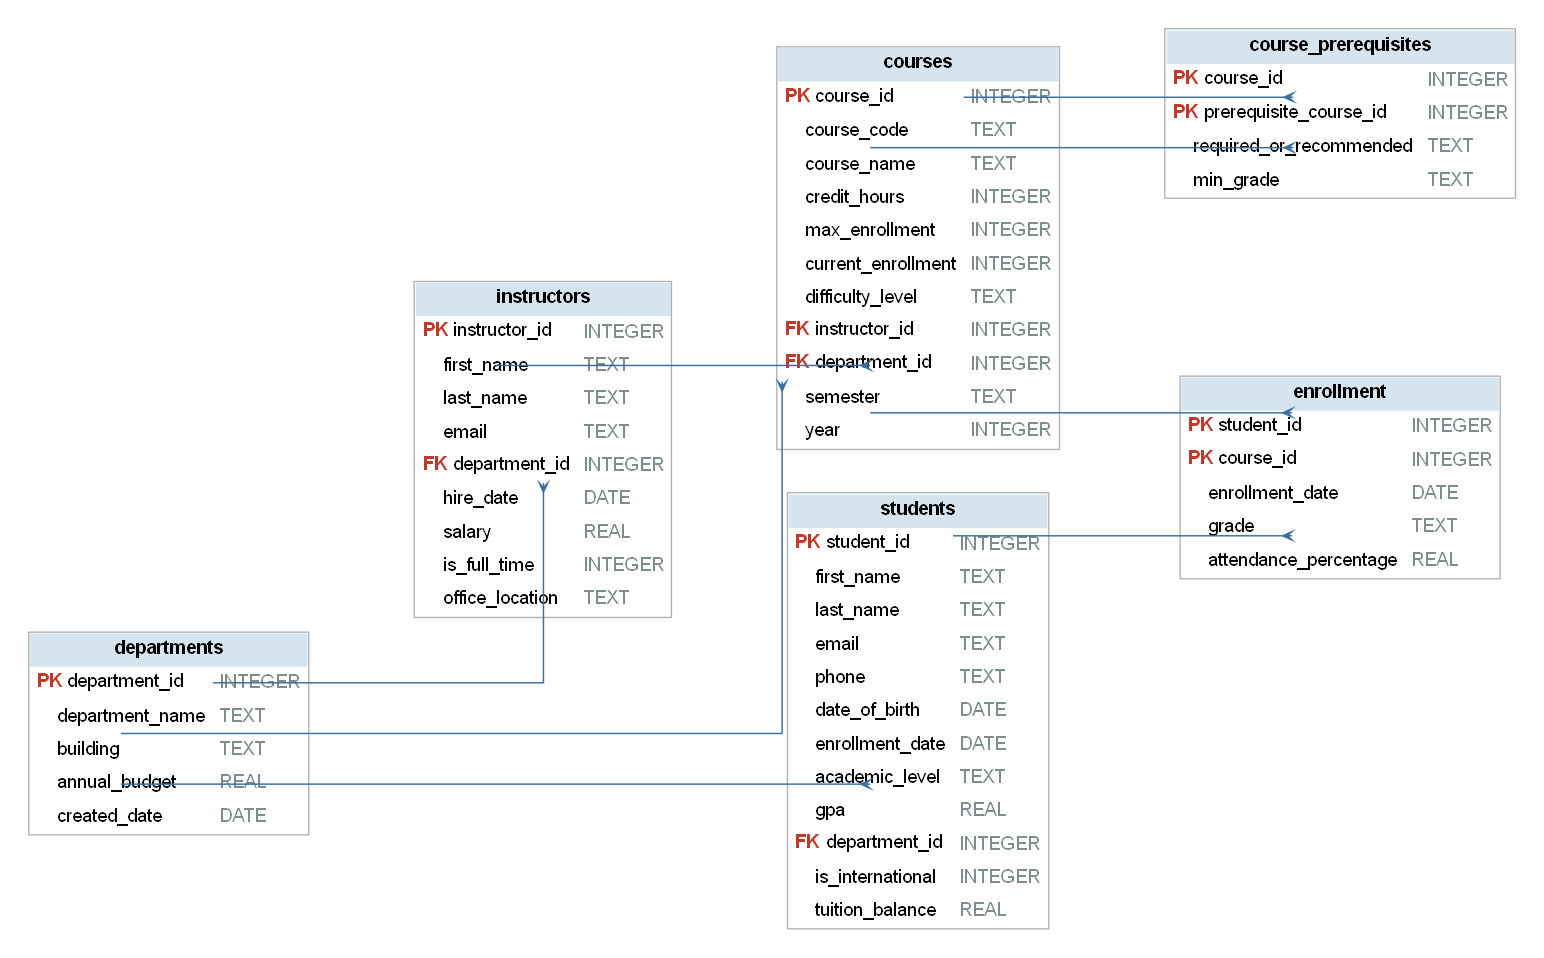

Saved → university_schema.png and university_schema.svg


In [5]:
import sqlite3
import html
from graphviz import Digraph
from IPython.display import display, Image

DB_NAME = "university_registration.db"
OUTPUT  = "university_schema"


def qi(name: str) -> str:
    """Safely quote an SQLite identifier."""
    return '"' + str(name).replace('"', '""') + '"'


conn = sqlite3.connect(DB_NAME)
cur  = conn.cursor()

cur.execute("""
    SELECT name FROM sqlite_master
    WHERE type = 'table' AND name NOT LIKE 'sqlite_%'
    ORDER BY name
""")
tables = [row[0] for row in cur.fetchall()]
if not tables:
    raise ValueError(f"No user tables found in {DB_NAME}")

schema = {}
for t in tables:
    cur.execute(f"PRAGMA table_info({qi(t)})")
    cols = cur.fetchall()

    cur.execute(f"PRAGMA foreign_key_list({qi(t)})")
    fks = cur.fetchall()

    schema[t] = {
        "columns": cols,
        "fks":     fks,
        "col_pos": {c[1]: i for i, c in enumerate(cols)},
        "fk_cols": {fk[3] for fk in fks},
    }

table_lookup = {t.lower(): t for t in tables}


dot = Digraph(
    name="University Registration Database",
    format="png",
    graph_attr={
        "rankdir":  "LR",
        "splines":  "ortho",
        "nodesep":  "0.45",
        "ranksep":  "1.10",
        "pad":      "0.30",
        "bgcolor":  "white",
        "fontname": "Helvetica",
    },
    node_attr={"shape": "plain", "fontname": "Helvetica"},
    edge_attr={
        "color":     "#3C6E9F",
        "penwidth":  "1.1",
        "arrowsize": "0.7",
    },
)


for t in tables:
    info = schema[t]
    rows = []

    for cid, name, ctype, _notnull, _dflt, pk in info["columns"]:
        tag = "PK" if pk else ("FK" if name in info["fk_cols"] else "")
        tag_html = (
            f'<FONT COLOR="#C0392B"><B>{tag}</B></FONT>&#160;'
            if tag else "&#160;&#160;&#160;&#160;"
        )

        rows.append(
            f'<TR>'
            f'<TD PORT="c{cid}" ALIGN="LEFT">{tag_html}{html.escape(str(name))}</TD>'
            f'<TD ALIGN="LEFT"><FONT COLOR="#7F8C8D">{html.escape(str(ctype or ""))}</FONT></TD>'
            f'</TR>'
        )

    label = (
        '<<TABLE BORDER="1" CELLBORDER="0" CELLSPACING="0" '
        'CELLPADDING="5" COLOR="#B0B0B0">'
        f'<TR><TD COLSPAN="2" BGCOLOR="#D6E4F0" ALIGN="CENTER">'
        f'<B>{html.escape(t)}</B></TD></TR>'
        + "".join(rows) +
        '</TABLE>>'
    )

    dot.node(t, label=label)


added = set()

for t in tables:
    info = schema[t]

    for fk in info["fks"]:
        ref_raw, from_col, to_col = fk[2], fk[3], fk[4]

        ref = table_lookup.get(str(ref_raw).lower())
        if ref is None:
            continue

        if not to_col:
            pks = [c[1] for c in schema[ref]["columns"] if c[5]]
            to_col = pks[0] if pks else None
        if to_col is None:
            continue

        src_i = info["col_pos"].get(from_col)
        dst_i = schema[ref]["col_pos"].get(to_col)
        if src_i is None or dst_i is None:
            continue

        parent_port = f"{ref}:c{dst_i}"
        child_port  = f"{t}:c{src_i}"

        if (parent_port, child_port) in added:
            continue
        added.add((parent_port, child_port))

        dot.edge(
            parent_port,
            child_port,
            arrowhead="crow",
            arrowtail="none",
        )


dot.render(filename=OUTPUT, format="png", cleanup=True)
dot.render(filename=OUTPUT, format="svg", cleanup=True)
display(Image(filename=f"{OUTPUT}.png"))
print(f"Saved → {OUTPUT}.png and {OUTPUT}.svg")

conn.close()